In [1]:
import IJulia
import Base64

# The julia kernel has built in support for Revise.jl, so this is the 
# recommended approach for long-running sessions:
# https://github.com/JuliaLang/IJulia.jl/blob/9b10fa9b879574bbf720f5285029e07758e50a5e/src/kernel.jl#L46-L51

# Users should enable revise within .julia/config/startup_ijulia.jl:
# https://timholy.github.io/Revise.jl/stable/config/#Using-Revise-automatically-within-Jupyter/IJulia-1

# clear console history
IJulia.clear_history()

fig_width = 7
fig_height = 5
fig_format = :retina
fig_dpi = 96

# no retina format type, use svg for high quality type/marks
if fig_format == :retina
  fig_format = :svg
elseif fig_format == :pdf
  fig_dpi = 96
  # Enable PDF support for IJulia
  IJulia.register_mime(MIME("application/pdf"))
end

# convert inches to pixels
fig_width = fig_width * fig_dpi
fig_height = fig_height * fig_dpi

# Intialize Plots w/ default fig width/height
try
  import Plots

  # Plots.jl doesn't support PDF output for versions < 1.28.1
  # so use png (if the DPI remains the default of 300 then set to 96)
  if (Plots._current_plots_version < v"1.28.1") & (fig_format == :pdf)
    Plots.gr(size=(fig_width, fig_height), fmt = :png, dpi = fig_dpi)
  else
    Plots.gr(size=(fig_width, fig_height), fmt = fig_format, dpi = fig_dpi)
  end
catch e
  # @warn "Plots init" exception=(e, catch_backtrace())
end

# Initialize CairoMakie with default fig width/height
try
  import CairoMakie

  # CairoMakie's display() in PDF format opens an interactive window
  # instead of saving to the ipynb file, so we don't do that.
  # https://github.com/quarto-dev/quarto-cli/issues/7548
  if fig_format == :pdf
    CairoMakie.activate!(type = "png")
  else
    CairoMakie.activate!(type = string(fig_format))
  end
  CairoMakie.update_theme!(resolution=(fig_width, fig_height))
catch e
    # @warn "CairoMakie init" exception=(e, catch_backtrace())
end
  
# Set run_path if specified
try
  run_path = "QzpcVXNlcnNcTmlrb2xhalxHaXRcZ3JhcGgtZXF1aWxpYnJpdW0tcmFkaWF0aXZlLXRyYW5zZmVyXGV4YW1wbGVz"
  if !isempty(run_path)
    run_path = String(Base64.base64decode(run_path))
    cd(run_path)
  end
catch e
  @warn "Run path init:" exception=(e, catch_backtrace())
end


# emulate old Pkg.installed beahvior, see
# https://discourse.julialang.org/t/how-to-use-pkg-dependencies-instead-of-pkg-installed/36416/9
import Pkg
function isinstalled(pkg::String)
  any(x -> x.name == pkg && x.is_direct_dep, values(Pkg.dependencies()))
end

# ojs_define
if isinstalled("JSON") && isinstalled("DataFrames")
  import JSON, DataFrames
  global function ojs_define(; kwargs...)
    convert(x) = x
    convert(x::DataFrames.AbstractDataFrame) = Tables.rows(x)
    content = Dict("contents" => [Dict("name" => k, "value" => convert(v)) for (k, v) in kwargs])
    tag = "<script type='ojs-define'>$(JSON.json(content))</script>"
    IJulia.display(MIME("text/html"), tag)
  end
elseif isinstalled("JSON")
  import JSON
  global function ojs_define(; kwargs...)
    content = Dict("contents" => [Dict("name" => k, "value" => v) for (k, v) in kwargs])
    tag = "<script type='ojs-define'>$(JSON.json(content))</script>"
    IJulia.display(MIME("text/html"), tag)
  end
else
  global function ojs_define(; kwargs...)
    @warn "JSON package not available. Please install the JSON.jl package to use ojs_define."
  end
end


# don't return kernel dependencies (b/c Revise should take care of dependencies)
nothing


In [2]:
#| echo: false
#| output: asis
using RayTraceHeatTransfer                         # needed here for its version number
println("*Rendered with RayTraceHeatTransfer.jl v", pkgversion(RayTraceHeatTransfer), " and Julia ", VERSION, ".*")

*Rendered with RayTraceHeatTransfer.jl v0.22.0 and Julia 1.13.2.*


In [3]:
using RayTraceHeatTransfer                         # the GERT solver
using GeometryBasics, StaticArrays                 # points and fixed-size vectors for the geometry

R            = 1.0                                 # radius of the star tips [m]
r            = 0.3                                 # radius of the inner pentagon's corners [m]
kappa        = 1.0                                 # absorption coefficient [m⁻¹]
source_total = 10000.0                             # total volumetric heat source over the whole star [W]
Ndiv         = 11                                  # subdivisions of every triangle

tip(k)   = Point2(R * cosd(90 + 72k), R * sind(90 + 72k))     # tip of arm k, the first pointing straight up
inner(k) = Point2(r * cosd(126 + 72k), r * sind(126 + 72k))   # pentagon corner between arm k and arm k + 1
centre   = Point2(0.0, 0.0)                        # centre of the star

faces = PolyVolume2D{Float64}[]                    # the 10 coarse triangles
for k in 0:4                                       # one centre triangle and one arm per corner of the pentagon
    # Centre triangle: centre → corner k−1 → corner k, counter-clockwise; every edge is open
    centre_tri = PolyVolume2D{Float64}(SVector(centre, inner(k - 1), inner(k)),
                                       SVector(false, false, false), 1, kappa, 0.0)
    centre_tri.T_in_w  = [0.0, 0.0, 0.0]           # no walls, so no wall temperatures are used
    centre_tri.epsilon = [1.0, 1.0, 1.0]           # no walls, so no emissivities are used
    centre_tri.T_in_g  = -1.0                      # gas temperature unknown; its heat source is set below
    push!(faces, centre_tri)                       # add it to the domain

    # Arm triangle: corner k−1 → tip k → corner k, counter-clockwise; the two outer edges are walls, the base is open
    arm_tri = PolyVolume2D{Float64}(SVector(inner(k - 1), tip(k), inner(k)),
                                    SVector(true, true, false), 1, kappa, 0.0)
    arm_tri.T_in_w  = [0.0, 0.0, 0.0]              # outer walls at 0 K (the base entry is unused)
    arm_tri.epsilon = [1.0, 1.0, 1.0]              # black outer walls
    arm_tri.T_in_g  = -1.0                         # gas temperature unknown; its heat source is set below
    push!(faces, arm_tri)                          # add it to the domain
end

area_total = sum(face.volume for face in faces)    # total area of the star (the "volume" of a 2D element) [m²]
q_density  = source_total / area_total             # uniform heat source density [W/m²]
for face in faces                                  # every triangle gets the same source density ...
    face.q_in_g = q_density * face.volume          # ... so its heat source is proportional to its area [W]
end

mesh = RayTracingDomain2D(faces, fill((Ndiv, Ndiv), length(faces)); verbose = false)   # every triangle subdivided 11 × 11
println("star area: ", round(area_total; digits = 4), " m², heat source density: ", round(q_density; digits = 1), " W/m²")

star area: 0.8817 m², heat source density: 11342.0 W/m²


In [4]:
mesh(10^8; method = :exchange, verbose = false)           # exchange factors by ray tracing (Sobol sampler)
smooth!(mesh; verbose = false)                            # enforce energy conservation and reciprocity
solveEquilibrium!(mesh, mesh.F_smooth; verbose = false)   # solve the GERT system

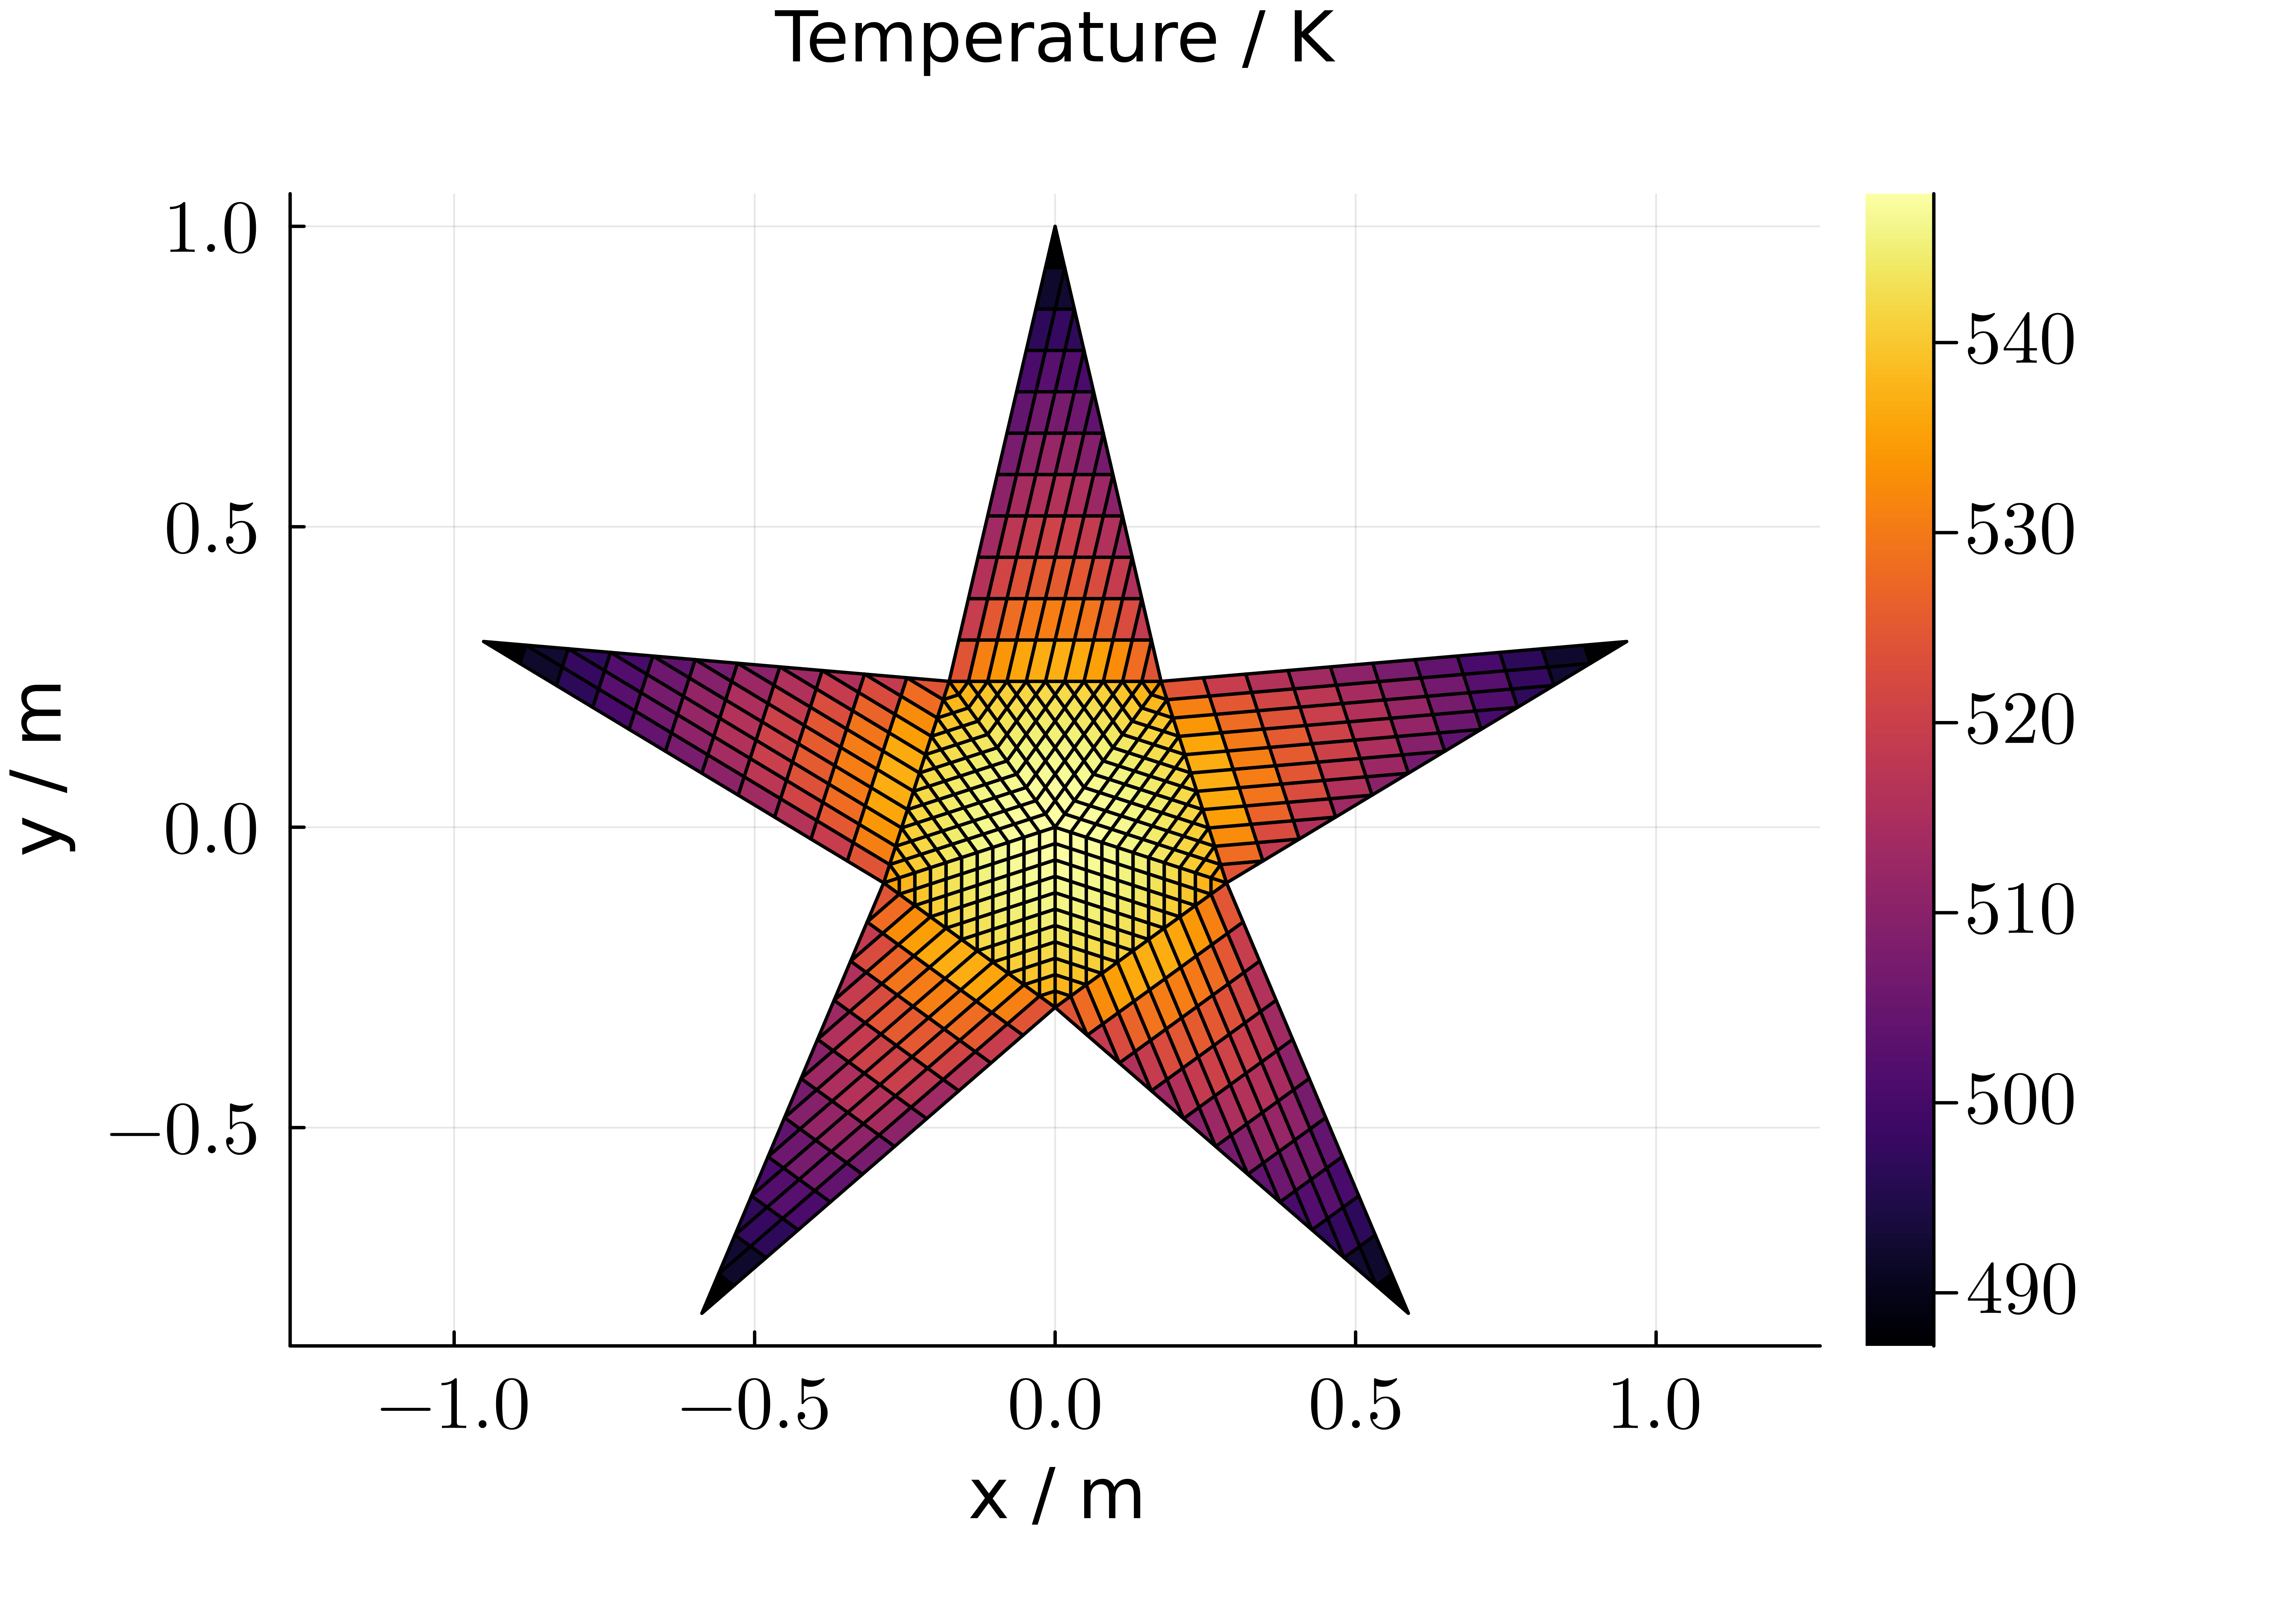

In [5]:
using Plots

p = plotField(mesh; field = :T)                    # gas temperature in every cell
Plots.plot!(p; xlabel = "x / m", ylabel = "y / m", # axis labels
            title = "Temperature / K",             # the field shown by the colour bar
            aspect_ratio = :equal)                 # keep the star's shape

In [6]:
q_gas  = sum(cell.q_g for fine in mesh.fine_mesh for cell in fine)   # heat released in the gas [W]
q_wall = sum(cell.q_w[i] for fine in mesh.fine_mesh for cell in fine
             for i in eachindex(cell.solidWalls) if cell.solidWalls[i])   # net source of every wall element [W]
println("heat released in the gas : ", round(q_gas; digits = 3), " W")
println("heat removed by the walls: ", round(-q_wall; digits = 3), " W")
println("relative imbalance       : ", abs(q_gas + q_wall) / q_gas)

heat released in the gas : 10000.0 W
heat removed by the walls: 10000.0 W
relative imbalance       : 4.547473508864661e-15


In [7]:
# Largest temperature difference between corresponding cells of five rotated copies of a triangle
function symmetry_spread(copies)
    T = [[cell.T_g for cell in mesh.fine_mesh[f]] for f in copies]   # cell temperatures of every copy
    return maximum(maximum(Tc[i] for Tc in T) - minimum(Tc[i] for Tc in T)   # spread over the five copies ...
                   for i in eachindex(T[1]))                                  # ... in the worst cell
end

T_all = [cell.T_g for fine in mesh.fine_mesh for cell in fine]               # every gas temperature in the star
println("temperature range : ", round(minimum(T_all); digits = 1), " K to ", round(maximum(T_all); digits = 1), " K")
println("spread, arms      : ", round(symmetry_spread(2:2:10); sigdigits = 2), " K")   # arms are faces 2, 4, …, 10
println("spread, centre    : ", round(symmetry_spread(1:2:9); sigdigits = 2), " K")    # centre triangles are faces 1, 3, …, 9

temperature range : 487.2 K to 547.8 K


spread, arms      : 0.23 K
spread, centre    : 0.15 K
